# 사고 빈도 모델링 4주차: 회귀 성능 지표 (MAE · MSE · RMSE · R²)

> `사고빈도_모델링_음이항GLM.ipynb`에 이어지는 노트북. 0~3단계(전처리·분리)는 같은 코드를 그대로 쓰고, 4주차 과제를 새로 진행함
>
> 지난 주에 비교한 **포아송 GLM과 음이항 GLM(alpha 0.84)** 두 모델로 진행함

| 4주차 과제 | 이 노트북에서 하는 일 |
|---|---|
| 1. MAE · MSE · RMSE · R² 값 확인 | 포아송 · 음이항 GLM의 지표 비교 + 시각화 |
| 2. 이상치 유무에 따른 지표 비교 | 원본 칼럼에서 이상치 확인 → 칼럼마다 이상치를 그대로 둔 모델과 비교 → 이상치를 직접 넣어서 지표 변화 확인 |
| 3. 어떤 지표 조합으로 볼지 결정 | 1·2번 결과를 근거로 RMSE · MAE · R² 조합을 정함 |

In [1]:
import platform

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
import statsmodels.api as sm
from sklearn.base import BaseEstimator, RegressorMixin, TransformerMixin
from sklearn.compose import ColumnTransformer
from sklearn.metrics import mean_absolute_error, mean_poisson_deviance, mean_squared_error, r2_score
from sklearn.model_selection import train_test_split
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler

# 그래프 한글 폰트: Colab은 `!pip install koreanize-matplotlib` 후 실행, Windows·Mac은 기본 폰트 사용
try:
    import koreanize_matplotlib  # noqa: F401
except ImportError:
    plt.rcParams["font.family"] = {"Windows": "Malgun Gothic", "Darwin": "AppleGothic"}.get(platform.system(), "DejaVu Sans")
plt.rcParams["axes.unicode_minus"] = False   # 음수 부호(-) 깨짐 방지

In [2]:
# ================================================================ 0단계: 불러오기 + 고정 규칙 전처리 (지난 노트북과 같음)
freq = pd.read_csv("freMTPL2freq.csv")
print(f"계약 수: {len(freq):,} · 사고 {freq.ClaimNb.sum():,}건 · "
      f"1년당 사고율 {freq.ClaimNb.sum() / freq.Exposure.sum():.4f}")

# 묶음 번호 (3단계 분할용): 특성 8개가 모두 같은 행 = 같은 계약
FEAT = ["VehPower", "VehAge", "DrivAge", "BonusMalus", "VehBrand",
        "VehGas", "Density", "Region"]
freq["GroupID"] = freq.groupby(FEAT, sort=False).ngroup()

# [4주차 추가] 2단계 이상치 비교용: 상한 처리(clip) 전 원본 값을 따로 보관
freq_raw = freq.copy()

# 타깃 · 가입 기간: 사고 5건 이상은 4로, 1년 넘는 가입 기간은 1로 상한 처리
freq["ClaimNb"] = freq["ClaimNb"].clip(upper=4)
freq["Exposure"] = freq["Exposure"].clip(upper=1)

# 피처
freq = freq.drop(columns=["Area"])                     # Area는 Density를 6구간으로 자른 것 → 중복
AGE_BINS = [17, 21, 25, 30, 40, 50, 60, 70, 80, 101]
freq["VehAge"] = freq["VehAge"].clip(upper=20)
freq["BonusMalus"] = freq["BonusMalus"].clip(upper=150)
freq["DrivAgeBin"] = pd.cut(freq["DrivAge"], bins=AGE_BINS).astype(str)
freq["VehPower"] = freq["VehPower"].clip(upper=12).astype(str)
freq["logDensity"] = np.log(freq["Density"])

assert freq["Exposure"].between(0, 1, inclusive="right").all(), "Exposure가 0 이하 또는 1 초과"
assert "nan" not in set(freq["DrivAgeBin"]), "나이 구간에 안 들어간 운전자 있음"
print("[0] 고정 규칙 전처리 완료")

계약 수: 678,013 · 사고 36,102건 · 1년당 사고율 0.1007


[0] 고정 규칙 전처리 완료


In [3]:
# ================================================================ 1단계: 전처리 + 모델 설계 (지난 노트북과 같음)
NUM_COLS = ["VehAge", "BonusMalus", "logDensity"]                      # 연속형 피처
CAT_COLS = ["DrivAgeBin", "VehPower", "VehGas", "VehBrand", "Region"]  # 범주형 피처


class RareLevelMerger(BaseEstimator, TransformerMixin):
    """사고 수가 min_claims 미만인 범주를 Other로 합침 (fit은 train에서만)"""

    def __init__(self, cols=("Region", "VehBrand"), min_claims=200):
        self.cols = cols
        self.min_claims = min_claims

    def fit(self, X, y):
        claims = pd.Series(np.asarray(y), index=X.index)
        self.keep_ = {}
        for c in self.cols:
            total = claims.groupby(X[c]).sum()
            self.keep_[c] = set(total[total >= self.min_claims].index)
        return self

    def transform(self, X):
        X = X.copy()
        for c in self.cols:
            X[c] = X[c].where(X[c].isin(self.keep_[c]), "Other")
        return X


class SMPoissonGLM(BaseEstimator, RegressorMixin):
    """statsmodels 포아송 GLM을 sklearn 모양으로 감싼 것 (Exposure → offset = log(가입 기간))"""

    def __init__(self, alpha=0.0):
        self.alpha = alpha

    def _split(self, X):
        X = pd.DataFrame(X).copy()
        exposure = X.pop("Exposure") if "Exposure" in X else X.pop(X.columns[-1])
        return sm.add_constant(X, has_constant="add"), np.log(np.asarray(exposure, dtype=float))

    def fit(self, X, y):
        exog, offset = self._split(X)
        model = sm.GLM(np.asarray(y, dtype=float), exog, family=sm.families.Poisson(), offset=offset)
        self.result_ = model.fit()
        self.params_ = np.asarray(self.result_.params)
        return self

    def predict(self, X):
        exog, offset = self._split(X)
        return np.exp(exog.to_numpy(dtype=float) @ self.params_ + offset)


class SMNegBinGLM(SMPoissonGLM):
    """음이항 GLM: 분산 = 평균 + nb_alpha × 평균² (지난 노트북 6단계에서 고른 nb_alpha = 0.84)"""

    def __init__(self, nb_alpha=0.84):
        self.nb_alpha = nb_alpha

    def fit(self, X, y):
        exog, offset = self._split(X)
        family = sm.families.NegativeBinomial(alpha=self.nb_alpha)
        self.result_ = sm.GLM(np.asarray(y, dtype=float), exog, family=family, offset=offset).fit()
        self.params_ = np.asarray(self.result_.params)
        return self


def make_model(estimator, num_cols=NUM_COLS):
    # 희귀 범주 합치기 → 숫자는 표준화 · 범주는 원-핫 · Exposure는 그대로 통과(offset) → GLM
    # [4주차 추가] num_cols를 바꿀 수 있게 해서, 2단계에서 "이상치를 그대로 둔 칼럼"으로 바꿔 끼움
    encode = ColumnTransformer([
        ("num", StandardScaler(), list(num_cols)),
        ("cat", OneHotEncoder(drop="first", handle_unknown="ignore", sparse_output=False), CAT_COLS),
        ("offset", "passthrough", ["Exposure"]),
    ], verbose_feature_names_out=False).set_output(transform="pandas")
    return Pipeline([("rare", RareLevelMerger()), ("encode", encode), ("model", estimator)])


MODELS = {"포아송 GLM": lambda: SMPoissonGLM(), "음이항 GLM": lambda: SMNegBinGLM(nb_alpha=0.84)}
COLORS = {"포아송 GLM": "#dd8452", "음이항 GLM": "#55a868"}


print("[1] 스케일링 대상:", NUM_COLS, "· 원-핫 대상:", CAT_COLS)

[1] 스케일링 대상: ['VehAge', 'BonusMalus', 'logDensity'] · 원-핫 대상: ['DrivAgeBin', 'VehPower', 'VehGas', 'VehBrand', 'Region']


In [4]:
# ================================================================ 2~3단계: X, Y 추출 + 묶음 단위 분리 (지난 노트북과 같음)
X = freq[["Exposure"] + NUM_COLS + CAT_COLS].copy()
y = freq["ClaimNb"].copy()
groups = freq["GroupID"].copy()

group_claim = freq.groupby("GroupID")["ClaimNb"].max().clip(upper=1)
g_train, g_test = train_test_split(group_claim.index, test_size=0.2, random_state=42,
                                   stratify=group_claim)
is_train = groups.isin(g_train)

X_train, X_test = X[is_train].copy(), X[~is_train].copy()
y_train, y_test = y[is_train].copy(), y[~is_train].copy()
assert set(groups[is_train]).isdisjoint(groups[~is_train]), "같은 묶음이 train과 test에 모두 있음"
print(f"[2~3] X {X.shape[0]:,}행 × {X.shape[1]}열 · train {len(X_train):,} / test {len(X_test):,}")

[2~3] X 678,013행 × 9열 · train 542,576 / test 135,437


## 과제 1단계: MAE · MSE · RMSE · R² 값 확인

| 지표 | 계산 | 의미 | 좋은 방향 |
|---|---|---|---|
| **MAE** | 평균( \|실제 − 예측\| ) | 전형적인 오차 크기. 단위가 "사고 건수"라 바로 읽힘 | 작을수록 |
| **MSE** | 평균( (실제 − 예측)² ) | 오차를 제곱해서 평균. 큰 오차에 벌점이 커짐 | 작을수록 |
| **RMSE** | √MSE | MSE를 원래 단위(건)로 되돌린 값. 큰 오차 존재 여부 | 작을수록 |
| **R²** | 1 − (모델 오차² 합 / 평균으로 예측했을 때 오차² 합) | "모두 평균으로 예측"보다 얼마나 나은지 = 설명력 | 1에 가까울수록 |

비교 모델: **포아송 GLM**, **음이항 GLM(alpha 0.84)** — 둘 다 가입 기간을 offset으로 넣음

In [5]:
# ================================================================ 과제 1단계: 지표 계산
def regression_metrics(y_true, pred):
    mse = mean_squared_error(y_true, pred)
    return {"MAE": mean_absolute_error(y_true, pred), "MSE": mse,
            "RMSE": np.sqrt(mse), "R²": r2_score(y_true, pred)}


# 포아송 · 음이항 GLM 학습 (train으로만)
fitted = {name: make_model(make()).fit(X_train, y_train) for name, make in MODELS.items()}
pred_test = {name: m.predict(X_test) for name, m in fitted.items()}

metrics_test = pd.DataFrame({name: regression_metrics(y_test, p) for name, p in pred_test.items()}).T
metrics_train = pd.DataFrame({name: regression_metrics(y_train, m.predict(X_train)) for name, m in fitted.items()}).T
print("[1단계] test 지표 (MAE·MSE·RMSE는 작을수록, R²는 클수록 좋음)")
print(metrics_test.round(5).to_string())
print("\n    train 지표 (test와 비슷하면 과적합 없음)")
print(metrics_train.round(5).to_string())

# 참고: MAE를 해석할 때 필요한 기준값 (모델 비교 대상은 아님)
# 사고 0건 계약이 대부분이라, "모두 0건"이라고만 답해도 MAE가 얼마나 나오는지 확인
mae_all_zero = mean_absolute_error(y_test, np.zeros(len(y_test)))
print(f"\n    참고: test 사고 0건 비율 {(y_test == 0).mean():.1%} · '모두 0건' 예측의 MAE {mae_all_zero:.4f}")

[1단계] test 지표 (MAE·MSE·RMSE는 작을수록, R²는 클수록 좋음)
             MAE      MSE     RMSE       R²
포아송 GLM  0.09908  0.05659  0.23789  0.00928
음이항 GLM  0.09957  0.05663  0.23796  0.00866

    train 지표 (test와 비슷하면 과적합 없음)
             MAE      MSE     RMSE       R²
포아송 GLM  0.09844  0.05587  0.23637  0.01112
음이항 GLM  0.09893  0.05590  0.23644  0.01051

    참고: test 사고 0건 비율 94.9% · '모두 0건' 예측의 MAE 0.0535


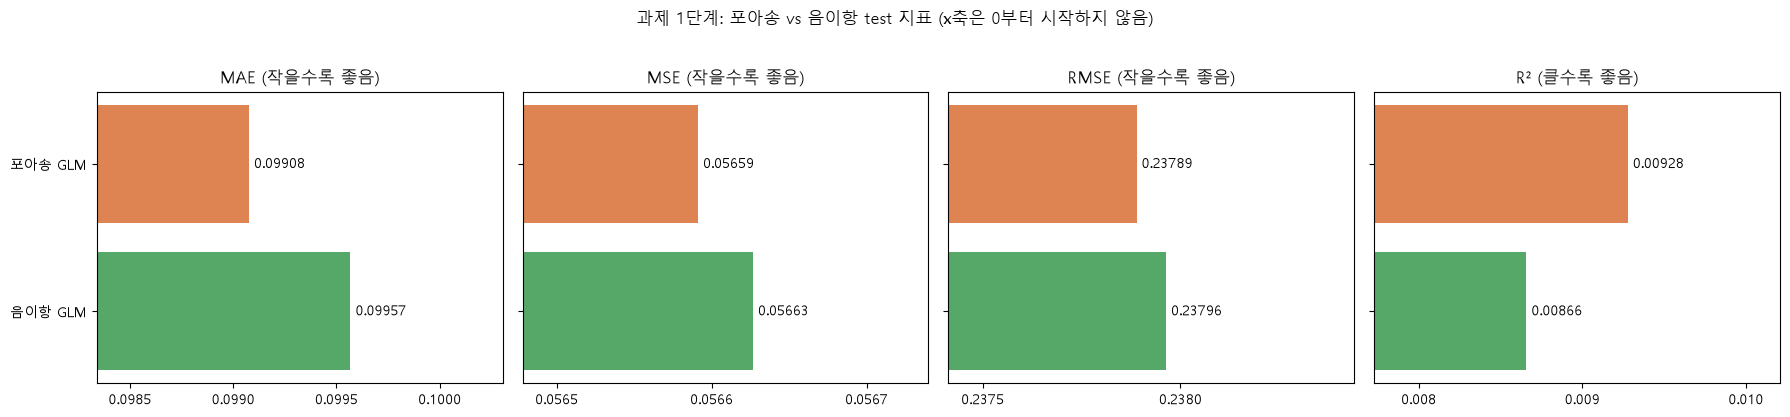

In [6]:
# ---------------------------------------------------------------- 과제 1단계 시각화 ①: 모델별 지표 막대그래프
models = list(metrics_test.index)
colors = [COLORS[m] for m in models]
fig, axes = plt.subplots(1, 4, figsize=(18, 4))
for ax, metric in zip(axes, ["MAE", "MSE", "RMSE", "R²"]):
    values = metrics_test[metric]
    ax.barh(models, values, color=colors)
    ax.set_title(metric + (" (클수록 좋음)" if metric == "R²" else " (작을수록 좋음)"))
    lo, hi = values.min(), values.max()
    pad = max((hi - lo) * 1.5, abs(hi) * 0.002)
    ax.set_xlim(lo - pad, hi + pad)                                  # 차이가 작아서 0부터 그리지 않음
    ax.locator_params(axis="x", nbins=4)                             # 축 숫자 겹침 방지
    for i, v in enumerate(values):
        ax.text(v, i, f" {v:.5f}", va="center", fontsize=10)
    ax.invert_yaxis()
for ax in axes[1:]:
    ax.set_yticklabels([])
fig.suptitle("과제 1단계: 포아송 vs 음이항 test 지표 (x축은 0부터 시작하지 않음)", y=1.03)
plt.tight_layout()
plt.show()

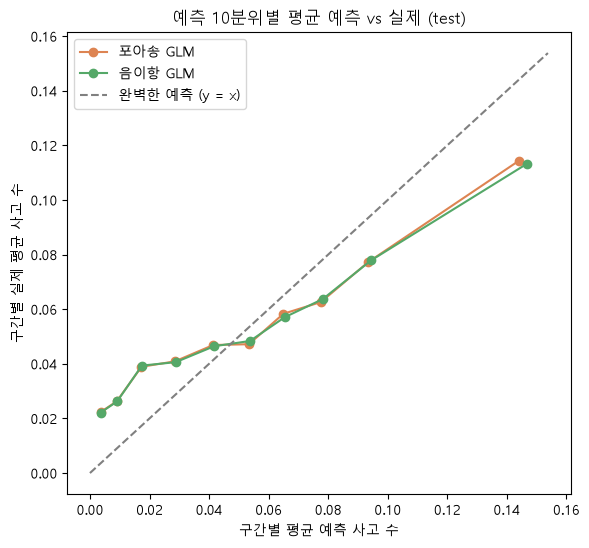

In [7]:
# ---------------------------------------------------------------- 과제 1단계 시각화 ②: 예측 10분위별 평균 예측 vs 실제
# 예측값 순으로 10개 구간으로 나눠, 구간마다 "평균 예측 사고 수"와 "실제 평균 사고 수"를 비교
# 대각선(y = x)에 가까울수록 평균을 잘 맞춘 모델
fig, ax = plt.subplots(figsize=(6.5, 6))
for name, p in pred_test.items():
    decile = pd.qcut(pd.Series(p).rank(method="first"), 10, labels=False)
    calib = pd.DataFrame({"pred": p, "actual": y_test.to_numpy(), "decile": decile}).groupby("decile").mean()
    ax.plot(calib["pred"], calib["actual"], marker="o", label=name, color=COLORS[name])
lim = [0, max(ax.get_xlim()[1], ax.get_ylim()[1])]
ax.plot(lim, lim, ls="--", color="gray", label="완벽한 예측 (y = x)")
ax.set_xlabel("구간별 평균 예측 사고 수")
ax.set_ylabel("구간별 실제 평균 사고 수")
ax.set_title("예측 10분위별 평균 예측 vs 실제 (test)")
ax.legend()
plt.show()

### 과제 1단계 해석

| 모델 (test) | MAE | MSE | RMSE | R² |
|---|---|---|---|---|
| 포아송 GLM | **0.09908** | **0.05659** | **0.23789** | **0.00928** |
| 음이항 GLM | 0.09957 | 0.05663 | 0.23796 | 0.00866 |

- **네 지표 모두 포아송이 아주 조금 앞선다.** 하지만 차이는 매우 작다. RMSE 차이는 0.00007(0.03%)이고, 그래프 ②에서도 두 모델의 선이 거의 겹친다. 평균 사고 수를 맞히는 능력은 사실상 같다.
- train과 test 지표가 비슷해서(포아송 RMSE 0.2364 / 0.2379) 과적합은 없다.
- **MAE는 이 데이터에서 단독으로 쓰기 어렵다.** test 계약의 94.9%가 사고 0건이라, 모델 없이 "모두 0건"이라고만 답해도 MAE가 0.0535로 두 모델(약 0.099)보다 작게 나온다. MAE는 중앙값(여기서는 0)을 맞힐 때 가장 작아지는 지표이기 때문이다.
- R²가 0.01 수준으로 낮은 건 정상이다. 사고는 우연의 영향이 커서 계약 하나하나를 맞히기는 원래 어렵다.
- 그래프 ②를 보면 두 모델 모두 예측이 작은 구간은 실제보다 낮게, 큰 구간은 실제보다 높게 예측한다. 가입 기간에 정비례한다는 offset 가정이 짧은 계약에서 맞지 않는 영향으로 보인다(지난 주 분석과 같은 원인).

## 과제 2단계: 이상치 유무에 따른 지표 비교

0단계 전처리에서 이미 이상치를 상한 처리(clip)했기 때문에, 원본 값(`freq_raw`)으로 돌아가서 비교함

1. **이상치 확인**: 원본 칼럼에서 IQR 기준(Q3 + 1.5 × IQR 초과)으로 이상치 개수를 세고 상자 그림으로 확인
2. **칼럼별 비교**: 한 칼럼씩 "이상치를 그대로 둔" 포아송 · 음이항 GLM을 학습해서, 전부 처리한 기준 모델과 test 지표를 비교
3. **직접 넣어 보기**: test 정답에 극단적인 사고 건수를 일부러 넣어서 MAE · RMSE · R²가 각각 얼마나 흔들리는지 확인

In [8]:
# ================================================================ 과제 2단계 ①: 원본 칼럼의 이상치 확인 (IQR 기준)
check_cols = {"ClaimNb": "4건으로 상한", "Exposure": "1년으로 상한", "VehAge": "20년으로 상한",
              "BonusMalus": "150으로 상한", "Density": "log 변환", "DrivAge": "나이 구간으로 묶음"}
rows = []
for col, how in check_cols.items():
    s = freq_raw[col]
    q1, q3 = s.quantile([0.25, 0.75])
    upper = q3 + 1.5 * (q3 - q1)
    n_out = int((s > upper).sum())
    rows.append({"칼럼": col, "Q1": q1, "Q3": q3, "이상치 기준(초과)": upper, "최댓값": s.max(),
                 "이상치 수": n_out, "비율(%)": round(n_out / len(s) * 100, 2), "0단계 처리": how})
outlier_table = pd.DataFrame(rows).set_index("칼럼")
print("[2단계 ①] 원본 칼럼 IQR 이상치")
print(outlier_table.to_string())
print("\n※ ClaimNb는 Q1 = Q3 = 0이라 IQR이 0 → 사고가 1건만 있어도 '이상치'로 잡힘."
      "\n  0이 대부분인 건수 데이터에는 IQR 기준이 맞지 않아서, 기록 오류로 보이는 5건 이상만 상한 처리함")

[2단계 ①] 원본 칼럼 IQR 이상치
               Q1       Q3  이상치 기준(초과)       최댓값  이상치 수  비율(%)      0단계 처리
칼럼                                                                        
ClaimNb      0.00     0.00       0.000     16.00  34060   5.02     4건으로 상한
Exposure     0.18     0.99       2.205      2.01      0   0.00     1년으로 상한
VehAge       2.00    11.00      24.500    100.00   3114   0.46    20년으로 상한
BonusMalus  50.00    64.00      85.000    230.00  62384   9.20    150으로 상한
Density     92.00  1658.00    4007.000  27000.00  77566  11.44      log 변환
DrivAge     34.00    55.00      86.500    100.00   1275   0.19  나이 구간으로 묶음

※ ClaimNb는 Q1 = Q3 = 0이라 IQR이 0 → 사고가 1건만 있어도 '이상치'로 잡힘.
  0이 대부분인 건수 데이터에는 IQR 기준이 맞지 않아서, 기록 오류로 보이는 5건 이상만 상한 처리함


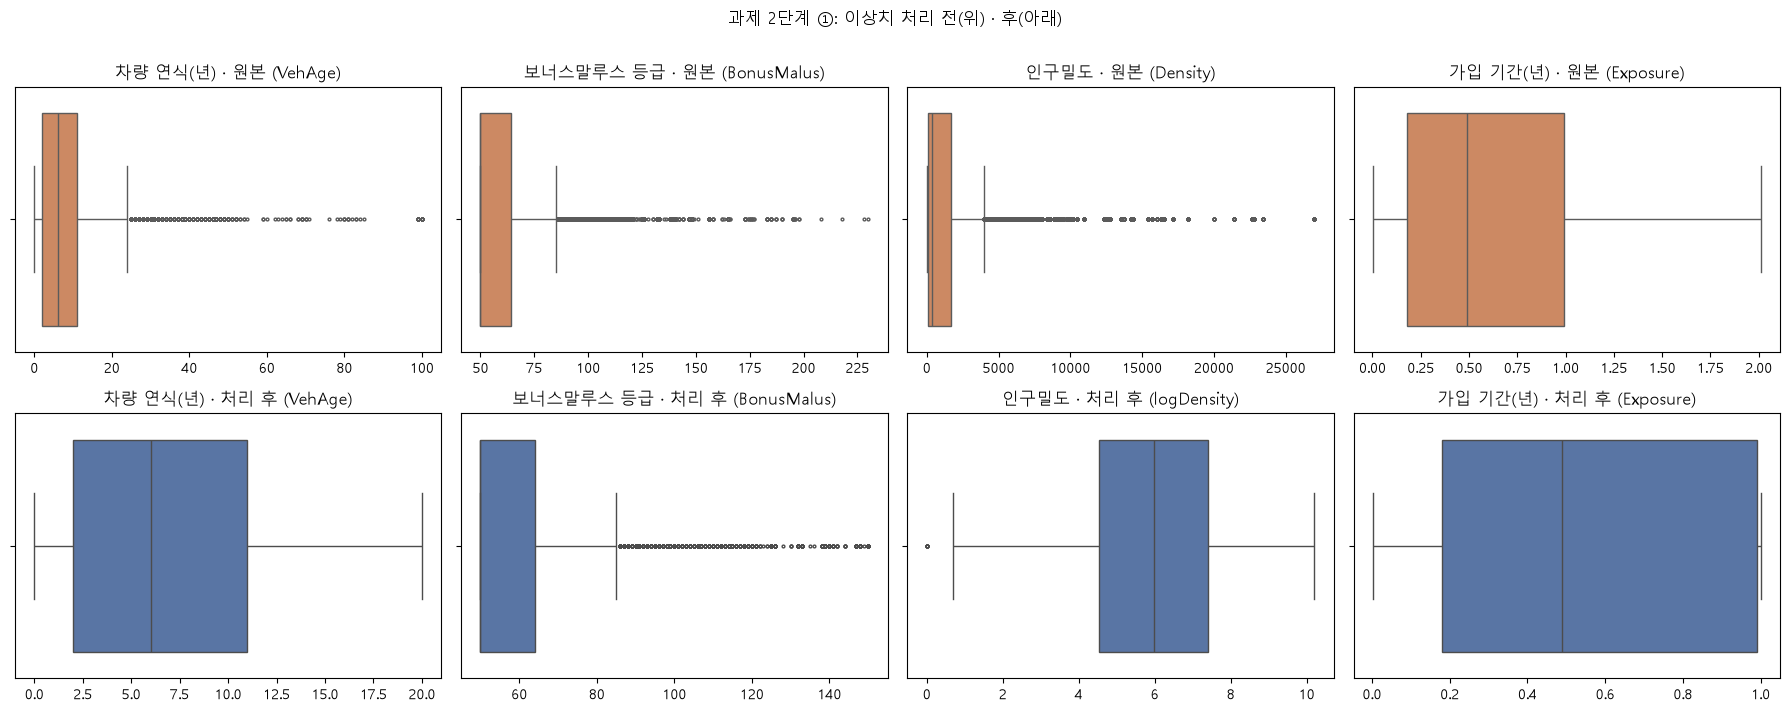

In [9]:
# ---------------------------------------------------------------- 과제 2단계 ① 시각화: 원본 vs 처리 후 상자 그림
pairs = [("VehAge", "VehAge", "차량 연식(년)"), ("BonusMalus", "BonusMalus", "보너스말루스 등급"),
         ("Density", "logDensity", "인구밀도"), ("Exposure", "Exposure", "가입 기간(년)")]
fig, axes = plt.subplots(2, 4, figsize=(18, 7))
for j, (raw_col, prep_col, label) in enumerate(pairs):
    sns.boxplot(x=freq_raw[raw_col], ax=axes[0, j], color="#dd8452", fliersize=2)
    axes[0, j].set_title(f"{label} · 원본 ({raw_col})")
    sns.boxplot(x=freq[prep_col], ax=axes[1, j], color="#4c72b0", fliersize=2)
    axes[1, j].set_title(f"{label} · 처리 후 ({prep_col})")
    for i in range(2):
        axes[i, j].set_xlabel("")
fig.suptitle("과제 2단계 ①: 이상치 처리 전(위) · 후(아래)", y=1.01)
plt.tight_layout()
plt.show()

In [10]:
# ================================================================ 과제 2단계 ②: 칼럼마다 이상치를 그대로 둔 모델과 비교
# 기준: 0단계처럼 전부 처리한 모델 (1단계와 같음)
# 변형: 한 칼럼만 원본 값으로 되돌려서 다시 학습 (나머지는 그대로) → 포아송 · 음이항 각각
# 평가: test는 두 가지 정답으로 계산
#   - "처리된 정답": 1단계와 같은 ClaimNb(4건 상한)
#   - "원본 정답": 상한 처리 전 실제 기록 (타깃 이상치가 지표에 주는 영향 확인용)
raw = freq_raw.loc[X.index]
y_test_raw = raw.loc[~is_train, "ClaimNb"]
print(f"test에서 원본 사고 건수가 4건을 넘는 계약: {(y_test_raw > 4).sum()}개 "
      f"(최댓값 {y_test_raw.max()}건)")


def run_variant(model_name, feature_raw=(), target_raw=False):
    """feature_raw에 적은 칼럼만 원본 값으로 되돌려 학습 → test 지표"""
    Xv = X.copy()
    num_cols = list(NUM_COLS)
    for col in feature_raw:
        if col == "Density":                       # log 변환 전 원본 인구밀도로 교체
            Xv["Density"] = raw["Density"]
            num_cols[num_cols.index("logDensity")] = "Density"
        else:                                      # Exposure 원본(1년 초과 포함)은 offset으로 그대로 들어감
            Xv[col] = raw[col]
    yv_train = raw.loc[is_train, "ClaimNb"] if target_raw else y_train
    model = make_model(MODELS[model_name](), num_cols).fit(Xv[is_train], yv_train)
    p = model.predict(Xv[~is_train])
    return {**{f"{k} (처리된 정답)": v for k, v in regression_metrics(y_test, p).items()},
            **{f"{k} (원본 정답)": v for k, v in regression_metrics(y_test_raw, p).items()}}


variants = {
    "기준: 전부 처리": {},
    "VehAge 이상치 유지": {"feature_raw": ["VehAge"]},
    "BonusMalus 이상치 유지": {"feature_raw": ["BonusMalus"]},
    "Density 원본(log 안 함)": {"feature_raw": ["Density"]},
    "Exposure 이상치 유지": {"feature_raw": ["Exposure"]},
    "ClaimNb(타깃) 이상치 유지": {"target_raw": True},
    "전부 원본": {"feature_raw": ["VehAge", "BonusMalus", "Density", "Exposure"], "target_raw": True},
}
outlier_result = {}                                # 모델 이름 → 변형별 지표 표
for model_name in MODELS:
    outlier_result[model_name] = pd.DataFrame({v: run_variant(model_name, **kw) for v, kw in variants.items()}).T

show = ["MAE (처리된 정답)", "RMSE (처리된 정답)", "R² (처리된 정답)", "RMSE (원본 정답)", "R² (원본 정답)"]
for model_name, table in outlier_result.items():
    print(f"\n[2단계 ②] 이상치 유무에 따른 {model_name} test 지표")
    print(table[show].round(5).to_string())

test에서 원본 사고 건수가 4건을 넘는 계약: 5개 (최댓값 16건)



[2단계 ②] 이상치 유무에 따른 포아송 GLM test 지표
                     MAE (처리된 정답)  RMSE (처리된 정답)  R² (처리된 정답)  RMSE (원본 정답)  R² (원본 정답)
기준: 전부 처리                 0.09908        0.23789      0.00928       0.24373     0.00862
VehAge 이상치 유지             0.09908        0.23789      0.00928       0.24373     0.00862
BonusMalus 이상치 유지         0.09909        0.23792      0.00898       0.24377     0.00834
Density 원본(log 안 함)       0.09910        0.23793      0.00893       0.24378     0.00828
Exposure 이상치 유지           0.09908        0.23790      0.00920       0.24374     0.00855
ClaimNb(타깃) 이상치 유지        0.09911        0.23789      0.00928       0.24373     0.00863
전부 원본                     0.09916        0.23798      0.00853       0.24382     0.00791

[2단계 ②] 이상치 유무에 따른 음이항 GLM test 지표
                     MAE (처리된 정답)  RMSE (처리된 정답)  R² (처리된 정답)  RMSE (원본 정답)  R² (원본 정답)
기준: 전부 처리                 0.09957        0.23796      0.00866       0.24381     0.00803
VehAge 이상치 유지             0.09957        0.23796

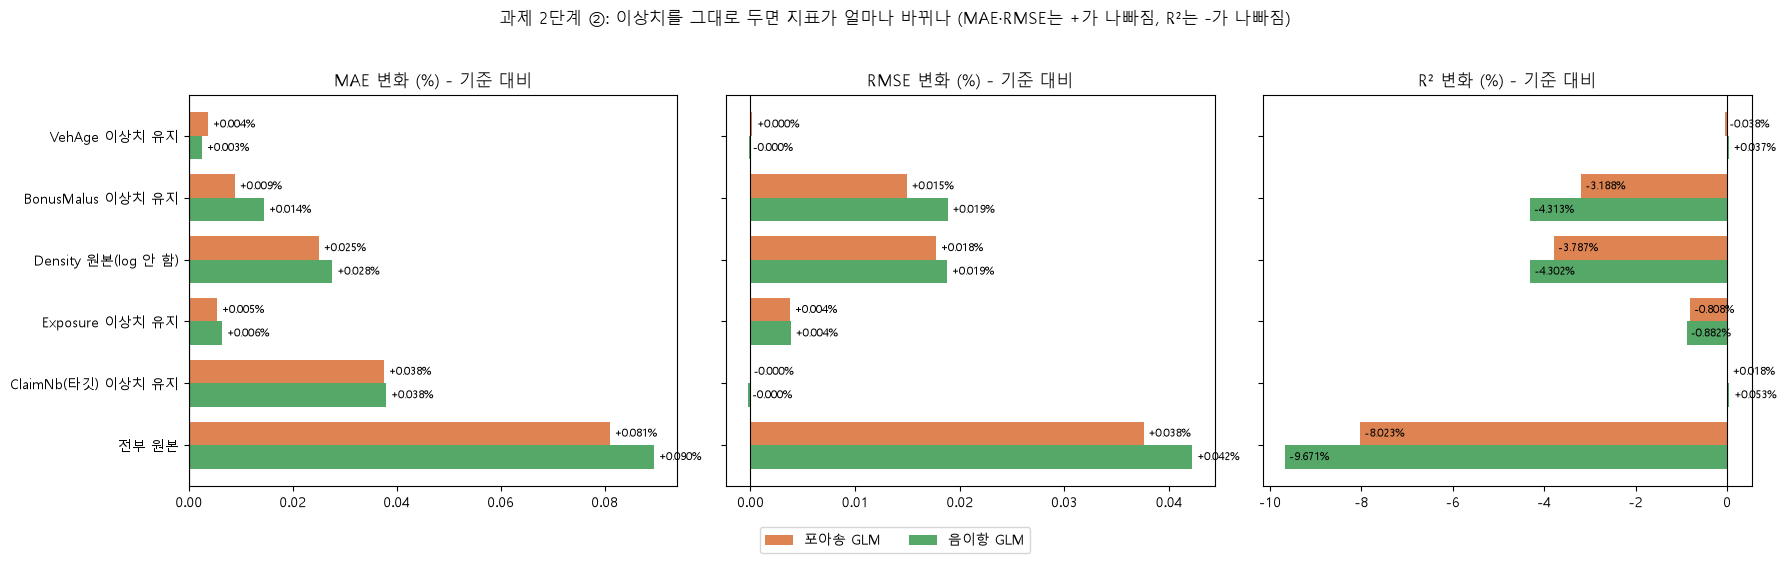

In [11]:
# ---------------------------------------------------------------- 과제 2단계 ② 시각화: 기준 대비 지표 변화(%)
metrics_show = ["MAE (처리된 정답)", "RMSE (처리된 정답)", "R² (처리된 정답)"]
fig, axes = plt.subplots(1, 3, figsize=(18, 5))
height = 0.38
for ax, metric in zip(axes, metrics_show):
    for k, (model_name, table) in enumerate(outlier_result.items()):
        change = (table[metric].drop(index="기준: 전부 처리") / table.loc["기준: 전부 처리", metric] - 1) * 100
        pos = np.arange(len(change)) + (k - 0.5) * height
        ax.barh(pos, change, height=height, color=COLORS[model_name], label=model_name)
        for p_, v in zip(pos, change):
            ax.text(v, p_, f" {v:+.3f}%", va="center", fontsize=8)
    ax.set_yticks(np.arange(len(change)))
    ax.set_yticklabels(change.index)
    ax.axvline(0, color="black", lw=0.8)
    ax.set_title(f"{metric.split(' ')[0]} 변화 (%) - 기준 대비")
    ax.invert_yaxis()
for ax in axes[1:]:
    ax.set_yticklabels([])
fig.legend(*axes[0].get_legend_handles_labels(), loc="lower center", ncol=2, bbox_to_anchor=(0.5, -0.07))
fig.suptitle("과제 2단계 ②: 이상치를 그대로 두면 지표가 얼마나 바뀌나 (MAE·RMSE는 +가 나빠짐, R²는 -가 나빠짐)", y=1.03)
plt.tight_layout()
plt.show()

[2단계 ③] 포아송 GLM: 사고 10건짜리 이상치를 test에 넣었을 때 (test 135,437개 중)
              MAE      MSE     RMSE       R²
넣은 이상치 수                                    
0         0.09908  0.05659  0.23789  0.00928
1         0.09915  0.05733  0.23943  0.00906
5         0.09944  0.06024  0.24543  0.00872
10        0.09981  0.06390  0.25279  0.00813
50        0.10269  0.09303  0.30501  0.00587
100       0.10637  0.12964  0.36005  0.00354
    이상치 0개 대비 변화(%)
          MAE    MSE  RMSE    R²
넣은 이상치 수                        
0         0.0    0.0   0.0   0.0
1         0.1    1.3   0.6  -2.3
5         0.4    6.4   3.2  -6.0
10        0.7   12.9   6.3 -12.4
50        3.6   64.4  28.2 -36.7
100       7.4  129.1  51.4 -61.8 

[2단계 ③] 음이항 GLM: 사고 10건짜리 이상치를 test에 넣었을 때 (test 135,437개 중)
              MAE      MSE     RMSE       R²
넣은 이상치 수                                    
0         0.09957  0.05663  0.23796  0.00866
1         0.09964  0.05736  0.23951  0.00845
5         0.09993  0.06027  0.24550  0.00815
10     

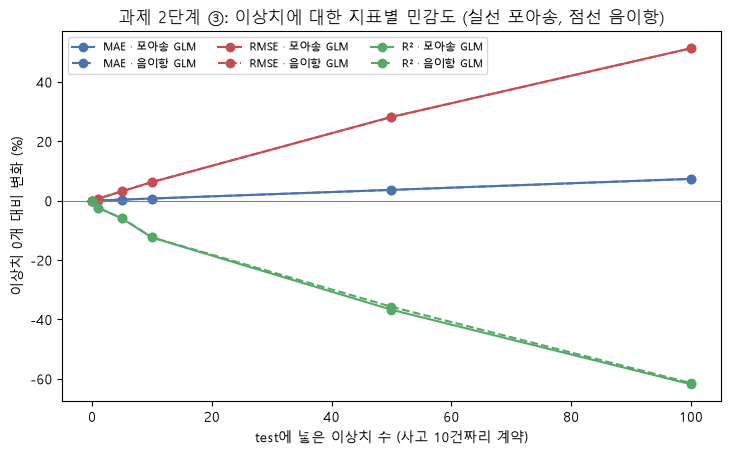

In [12]:
# ================================================================ 과제 2단계 ③: test 정답에 이상치를 직접 넣어 보기
# 모델(1단계 학습 결과)은 그대로 두고, test 계약 중 일부의 사고 건수를 10건으로 바꿈
# → 같은 예측값인데 정답에 극단값이 섞이면 각 지표가 얼마나 흔들리는지 확인
inject_change = {}
for model_name, p in pred_test.items():
    rng = np.random.default_rng(0)                             # 두 모델에 같은 계약을 바꾸도록 같은 시드
    rows = []
    for k in [0, 1, 5, 10, 50, 100]:
        y_inj = y_test.to_numpy().copy()
        idx = rng.choice(len(y_inj), size=k, replace=False)
        y_inj[idx] = 10                                        # 극단적인 사고 건수 10건
        rows.append({"넣은 이상치 수": k, **regression_metrics(y_inj, p)})
    inject = pd.DataFrame(rows).set_index("넣은 이상치 수")
    inject_change[model_name] = (inject / inject.loc[0] - 1) * 100
    print(f"[2단계 ③] {model_name}: 사고 10건짜리 이상치를 test에 넣었을 때 (test 135,437개 중)")
    print(inject.round(5).to_string())
    print("    이상치 0개 대비 변화(%)")
    print(inject_change[model_name].round(1).to_string(), "\n")

fig, ax = plt.subplots(figsize=(8.5, 4.8))
for metric, color in zip(["MAE", "RMSE", "R²"], ["#4c72b0", "#c44e52", "#55a868"]):
    for model_name, ls in zip(MODELS, ["-", "--"]):
        ch = inject_change[model_name][metric]
        ax.plot(ch.index, ch, marker="o", ls=ls, color=color, label=f"{metric} · {model_name}")
ax.axhline(0, color="gray", lw=0.8)
ax.set_xlabel("test에 넣은 이상치 수 (사고 10건짜리 계약)")
ax.set_ylabel("이상치 0개 대비 변화 (%)")
ax.set_title("과제 2단계 ③: 이상치에 대한 지표별 민감도 (실선 포아송, 점선 음이항)")
ax.legend(ncol=3, fontsize=8)
plt.show()

### 과제 2단계 해석

**① 원본 칼럼의 이상치 (IQR 기준)**

| 칼럼 | 이상치 수 (비율) | 최댓값 | 0단계 처리 |
|---|---|---|---|
| Density | 77,566개 (11.44%) | 27,000 | log 변환 |
| BonusMalus | 62,384개 (9.20%) | 230 | 150으로 상한 |
| VehAge | 3,114개 (0.46%) | 100 | 20으로 상한 |
| DrivAge | 1,275개 (0.19%) | 100 | 나이 구간으로 묶음 |
| Exposure | 0개 (IQR 기준) | 2.01 | 1년으로 상한 (1년 초과 1,224건은 기록 오차) |
| ClaimNb | IQR 사용 불가 | 16 | 4건으로 상한 (5건 이상 9건) |

**② 피처 이상치: MAE · RMSE는 거의 그대로, R²는 눈에 띄게 나빠짐**

| 이상치를 그대로 둔 칼럼 | 포아송 R² 변화 | 음이항 R² 변화 | MAE · RMSE 변화 |
|---|---|---|---|
| BonusMalus | -3.2% | -4.3% | 0.02% 이하 |
| Density (log 안 함) | -3.8% | -4.3% | 0.03% 이하 |
| Exposure | -0.8% | -0.9% | 0.01% 이하 |
| VehAge · ClaimNb(학습 타깃) | 거의 0 | 거의 0 | 0.04% 이하 |
| **전부 원본** | **-8.0%** | **-9.7%** | 0.09% 이하 |

- 이상치를 처리한 0단계 전처리가 R²(설명력) 기준으로 확실히 낫다. 특히 이상치가 많은 BonusMalus(9.2%)와 Density(11.4%)의 처리가 효과가 컸다.
- 음이항이 포아송보다 이상치에 조금 더 민감했다.
- MAE · RMSE가 거의 안 변한 이유: 학습 데이터가 54만 개라 예측값(평균) 자체는 크게 흔들리지 않기 때문이다. R²는 원래 값이 0.009로 작아서, 작은 변화도 비율로는 크게 보인다.

**③ 정답(타깃)의 이상치는 RMSE · R²를 크게 흔든다**
- 같은 모델인데 test 정답만 원본(사고 5건 이상 그대로)으로 바꾸면 포아송 RMSE가 0.2379 → 0.2437(+2.5%)로 나빠진다. test 135,437개 중 단 **5개**(최대 16건) 때문이다.
- 사고 10건짜리 이상치를 test에 직접 넣어 보면 차이가 분명하다(두 모델 거의 같음, 아래는 포아송).

| 넣은 이상치 수 | MAE 변화 | RMSE 변화 | R² 변화 |
|---|---|---|---|
| 10개 (0.007%) | +0.7% | +6.3% | -12.4% |
| 100개 (0.07%) | +7.4% | +51.4% | -61.8% |

- **MAE는 이상치에 강하고, RMSE와 R²는 아주 민감하다.** 슬라이드 설명처럼 MAE는 "전형적인 오차 크기", RMSE는 "큰 오차가 있는지"를 보여준다.
- 그래서 정답의 기록 오류(사고 5건 이상)를 4건으로 상한 처리한 0단계 결정이 RMSE · R²를 믿을 수 있게 만드는 데 중요하다.

## 과제 3단계: 어떤 지표 조합으로 볼지 결정

**결정: RMSE(주 지표) + R²(설명력) + MAE(보조) — 건수 데이터 참고용으로 Poisson deviance 함께**

| 지표 | 이번 데이터에서 확인한 것 | 역할 |
|---|---|---|
| **RMSE** | 평균을 맞히는 능력을 반영. 큰 오차(다건 사고)에 민감 (이상치 100개에 +51.4%) | **주 지표.** 보험료는 "평균 사고 수"로 정하므로 평균을 맞히는 능력이 가장 중요. 단, 타깃 이상치는 상한 처리한 뒤 사용 |
| **R²** | "모두 평균" 대비 개선 정도 (포아송 0.0093, 음이항 0.0087). 피처 이상치 처리 효과가 가장 잘 드러남 | **설명력.** 모델 · 전처리 비교에 사용. 값이 작은 건 사고가 우연의 영향이 큰 문제라서 |
| **MAE** | 이상치에 강함(+7.4%)이지만, "모두 0건 예측"(0.0535)이 두 모델(0.099)보다 좋게 나옴 | **보조.** 전형적인 오차 크기를 건 단위로 설명할 때만 쓰고, 단독으로 모델을 고르지 않음 |
| MSE | RMSE와 같은 정보, 단위가 건² | 보고하지 않음 (RMSE로 대신) |
| Poisson deviance | 건수 데이터 전용 지표. 두 모델 모두 0.3209 | 참고 (지난 주 주 지표) |

In [13]:
# ================================================================ 과제 3단계: 최종 지표 조합으로 정리
final = metrics_test[["RMSE", "R²", "MAE"]].copy()
final["Poisson deviance (참고)"] = [mean_poisson_deviance(y_test, p) for p in pred_test.values()]
print("[3단계] 최종 지표 조합: RMSE(주) + R²(설명력) + MAE(보조)  ·  건수 데이터 참고용 Poisson deviance")
print(final.round(5).to_string())
print(f"\n    예측 사고 건수 합: " + " / ".join(f"{n} {p.sum():,.0f}건" for n, p in pred_test.items())
      + f" / 실제 {y_test.sum():,}건")

[3단계] 최종 지표 조합: RMSE(주) + R²(설명력) + MAE(보조)  ·  건수 데이터 참고용 Poisson deviance
            RMSE       R²      MAE  Poisson deviance (참고)
포아송 GLM  0.23789  0.00928  0.09908                0.32087
음이항 GLM  0.23796  0.00866  0.09957                0.32087

    예측 사고 건수 합: 포아송 GLM 7,222건 / 음이항 GLM 7,302건 / 실제 7,246건
